# P2 AI pilot — scores, test and figures

This notebook re-creates every AI-pilot number in the paper from the saved files.

| Step | What it does |
|---|---|
| 1 | Re-runs the scoring script on all 60 answers (same locked rules) |
| 2 | Table 4: healthy score (Score A) and buyable-nearby score (Score B) by area type and chatbot |
| 3 | Test: do chatbots recommend fewer fresh foods in hidden food deserts? |
| 4 | Figure 3: share of recommended foods buyable nearby, hidden food-desert tracts |
| 5 | Address check: are the places real, and how far away? + Figure 4 |
| 6 | SNAP retailer check of grocery-store addresses (USDA FNS list) and final address codes |

In [1]:
from pathlib import Path
import pandas as pd, matplotlib.pyplot as plt, subprocess, sys
from scipy.stats import mannwhitneyu

SCORING = Path.cwd().parent / 'ai_pilot'
FIGS = Path.cwd().parent / 'figures'
print(SCORING.exists(), FIGS.exists())

True True


## 1. Re-run the scoring script
Reads `P2_AI_Pilot_Answers.docx`, applies the locked rules, writes `scores.csv` and the Audit Excel file. **Close the Excel and Word files first.** It should print `scored 60`.

In [2]:
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'python-docx', 'openpyxl'])
r = subprocess.run([sys.executable, str(SCORING / 'score_pilot.py')], capture_output=True, text=True)
print(r.stdout, r.stderr[-500:])

scored 60
 


## 2. Table 4 — Score A (healthy) and Score B (buyable nearby)
- **Score A** = share of 5 healthy-advice items present (0–1).
- **Score B** = share of recommended foods sold at the store types near the tract (0–1). Comparison tracts have a supermarket, so Score B = 1 by design.

In [3]:
d = pd.read_csv(SCORING / 'scores.csv')
d['not_sold'] = d.n_foods - d.n_sold
d['share_fresh'] = d.n_fresh / d.n_foods
t3 = d.groupby('group').agg(answers=('run','count'), score_A=('scoreA','mean'), foods=('n_foods','mean'),
                            not_sold=('not_sold','mean'), score_B=('scoreB','mean'), fresh_share=('share_fresh','mean')).round(2)
display(t3)
display(d.pivot_table(index='bot', columns='group', values=['scoreA','scoreB']).round(2))
display(d.pivot_table(index='metro', columns='group', values='scoreB').round(2))

,answers,score_A,foods,not_sold,score_B,fresh_share
group,,,,,,
Comparison,30,0.93,17.13,0.00,1.0,0.33
Hidden,30,0.89,16.00,4.83,0.7,0.30


scoreA            scoreB       
group   Comparison Hidden Comparison Hidden
bot                                        
ChatGPT       0.98   0.94        1.0   0.67
Claude        1.00   0.96        1.0   0.68
Gemini        0.80   0.76        1.0   0.76

group,Comparison,Hidden
metro,,
Metro Detroit,1.0,0.72
Metro Los Angeles,1.0,0.69


## 3. Test — fewer fresh foods in hidden food deserts?
Mann-Whitney test (compares two groups without assuming a bell curve).

In [4]:
h = d[d.group=='Hidden'].share_fresh; c = d[d.group=='Comparison'].share_fresh
print(f'Fresh share: Hidden {h.mean():.1%}  Comparison {c.mean():.1%}  p = {mannwhitneyu(h, c).pvalue:.3f}')

Fresh share: Hidden 29.6%  Comparison 32.9%  p = 0.047


## 4. Figure 3 — How much of the AI advice can be bought nearby? (hidden food-desert tracts)

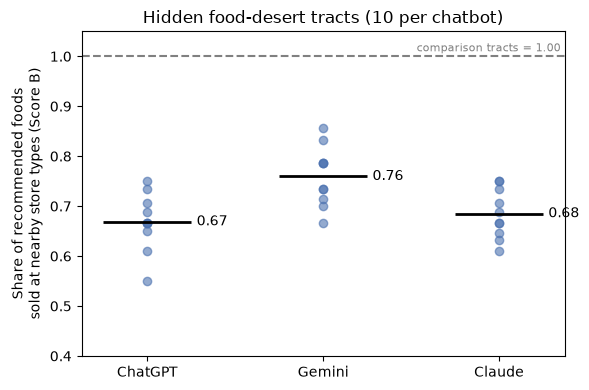

In [5]:
hd = d[d.group=='Hidden']
bots = ['ChatGPT','Gemini','Claude']
fig, ax = plt.subplots(figsize=(6,4))
for i, b in enumerate(bots):
    v = hd[hd.bot==b].scoreB
    ax.scatter([i]*len(v), v, alpha=.6, color='#4C72B0')
    ax.hlines(v.mean(), i-.25, i+.25, color='black', lw=2)
    ax.text(i+.28, v.mean(), f'{v.mean():.2f}', va='center')
ax.axhline(1, ls='--', color='grey'); ax.text(2.35, 1.01, 'comparison tracts = 1.00', ha='right', fontsize=8, color='grey')
ax.set_xticks(range(3)); ax.set_xticklabels(bots); ax.set_ylim(0.4, 1.05)
ax.set_ylabel('Share of recommended foods\nsold at nearby store types (Score B)')
ax.set_title('Hidden food-desert tracts (10 per chatbot)')
plt.tight_layout(); plt.savefig(FIGS/'fig3_ai_score_b.png', dpi=300); plt.show()

## 5. Address check — are the places real, and how far away?
Addresses located with the Census Geocoder; distance = straight line from the person's tract centre. Existence coded from web listings (one source each). For grocery stores, codes were also checked against the USDA SNAP retailer list (section 6), which corrected 4 places.

code,UNCLEAR,VERIFIED,VERIFIED_PLACE_ONLY,WRONG_ADDRESS,WRONG_NAME,All
bot,,,,,,
ChatGPT,2,35,1,2,1,41
Gemini,1,10,2,1,0,14
All,3,45,3,3,1,55


Located: 51 of 55 | median 1.3 mi | within 1 mi 27% | over 3 mi 22%


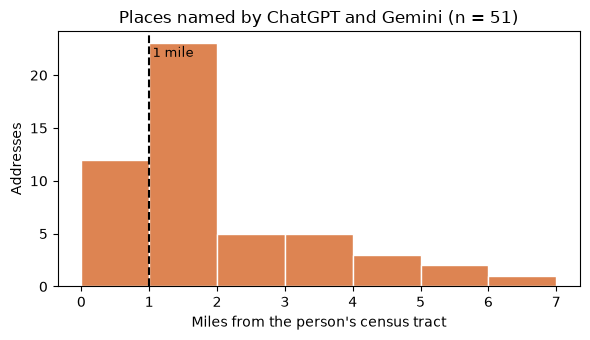

In [6]:
a = pd.read_csv(SCORING / 'addresses_final.csv')
display(pd.crosstab(a.bot, a.code, margins=True))
m = a.miles_from_tract.dropna()
print(f'Located: {len(m)} of {len(a)} | median {m.median():.1f} mi | within 1 mi {(m<=1).mean():.0%} | over 3 mi {(m>3).mean():.0%}')
fig, ax = plt.subplots(figsize=(6,3.5))
ax.hist(m, bins=range(0,8), color='#DD8452', edgecolor='white')
ax.axvline(1, ls='--', color='black'); ax.text(1.05, ax.get_ylim()[1]*.9, '1 mile', fontsize=9)
ax.set_xlabel('Miles from the person\'s census tract'); ax.set_ylabel('Addresses')
ax.set_title('Places named by ChatGPT and Gemini (n = %d)' % len(m))
plt.tight_layout(); plt.savefig(FIGS/'fig4_ai_address_distance.png', dpi=300); plt.show()

## 6. SNAP retailer check: are the named grocery stores real SNAP stores at that address?
Matches each chatbot address to the **USDA FNS Historical SNAP Retailer Locator data (2005–2025, current to Dec 31, 2025)**, file `data/raw/snap-retailer-locator-data2005-2025.zip`.

| Rule | Meaning |
|---|---|
| Same state + same street number | e.g. 740 in CA |
| Same core street name | directions and street types removed; K-4 = K4; EIGHT = 8 |
| Same city or ZIP | from the chatbot or the Census geocoder |
| Best record | direction match, store-name overlap, still active |

Script: `ai_pilot/snap_match.py` → writes `addresses_final_with_snap.csv`. Expected: **all 20 grocery stores matched as active SNAP stores**. Pantries and agencies are not SNAP stores, so they keep the web/hand-check codes.

In [10]:
r = subprocess.run([sys.executable, str(SCORING / 'snap_match.py')], capture_output=True, text=True)
print('script ran' if r.returncode == 0 else r.stderr[-800:])
sn = pd.read_csv(SCORING / 'addresses_final_with_snap.csv')
g = sn[sn.place_type == 'grocery']
print(f'Grocery stores named: {len(g)} | found in SNAP list at that address: {(g.snap_match=="Y").sum()} | '
      f'an active SNAP store at that address: {(g.snap_active_store_at_address=="Y").sum()}')
display(g[['id','bot','place_name','street','city','snap_store_name','snap_store_type','snap_active_2025','snap_active_store_name','code']])
# A11: the name the chatbot gave (Family Ranch Market) was last used in 2019; the store at that address is active under a new name.

script ran
Grocery stores named: 20 | found in SNAP list at that address: 20 | an active SNAP store at that address: 20


,id,bot,place_name,street,city,snap_store_name,snap_store_type,snap_active_2025,snap_active_store_name,code
6,A07,ChatGPT,Food 4 Less,2090 S Garey Ave,Pomona,FOOD 4 LESS 358,Super Store,Y,FOOD 4 LESS 358,VERIFIED
9,A10,ChatGPT,WinCo Foods,740 W Avenue K-4,Lancaster,WinCo Foods 35,Supermarket,Y,WinCo Foods 35,VERIFIED
10,A11,ChatGPT,Family Ranch Market,25926 S Western Ave,Harbor City,FAMILY RANCH MARKET,Medium Grocery Store,N (ended 8/4/2019),Mercado El Rey 0,VERIFIED
11,A12,ChatGPT,Food 4 Less,851 Sepulveda Blvd,Torrance,FOOD 4 LESS 368,Super Store,Y,FOOD 4 LESS 368,VERIFIED
13,A14,ChatGPT,Food 4 Less,11245 Long Beach Blvd,Lynwood,FOOD 4 LESS 324,Super Store,Y,FOOD 4 LESS 324,VERIFIED
14,A15,ChatGPT,El Super,10721 Atlantic Ave,Lynwood,El Super 44,Supermarket,Y,El Super 44,VERIFIED
17,A18,ChatGPT,JONS Fresh Marketplace,1601 N Vermont Ave,Los Angeles,JONS MARKET 11,Supermarket,Y,JONS MARKET 11,VERIFIED
18,A19,ChatGPT,Vons,4520 Sunset Blvd,Los Angeles,VONS 2665,Supermarket,Y,VONS 2665,VERIFIED
19,A20,ChatGPT,Albertsons,2035 Hillhurst Ave,Los Angeles,Albertsons 387,Supermarket,Y,Albertsons 387,VERIFIED
21,A22,ChatGPT,Food 4 Less,1091 S Hoover St,Los Angeles,FOOD 4 LESS 375,Super Store,Y,FOOD 4 LESS 375,VERIFIED


### Final address codes after the SNAP check (= Results 3.5)
Expected: 45 verified (82%), 7 clear problems (13%, all pantries or community programs), 3 unclear.

In [11]:
t = sn.code.value_counts()
prob = t.get('WRONG_ADDRESS',0)+t.get('WRONG_NAME',0)+t.get('VERIFIED_PLACE_ONLY',0)
print(f"Verified {t.get('VERIFIED',0)} of {len(sn)} ({t.get('VERIFIED',0)/len(sn):.0%}) | problems {prob} ({prob/len(sn):.0%}) | unclear {t.get('UNCLEAR',0)}")
display(sn[sn.code!='VERIFIED'][['id','bot','place_name','place_type','street','city','code','note']])

Verified 45 of 55 (82%) | problems 7 (13%) | unclear 3


,id,bot,place_name,place_type,street,city,code,note
1,A02,ChatGPT,Door of Hope Community Center,pantry,1200 W Mines Ave,Montebello,WRONG_ADDRESS,No evidence of anything at 1200 W Mines
7,A08,Gemini,El Lirio Food Pantry,pantry,44938 30th St E,Lancaster,UNCLEAR,Pantry exists; no street address published
12,A13,Gemini,San Pedro & Peninsula YMCA,pantry,301 S Bandini St,San Pedro,VERIFIED_PLACE_ONLY,YMCA real; weekly food distribution not confirmed
20,A21,Gemini,Anderson Munger Family YMCA,pantry,4301 W 3rd St,Los Angeles,VERIFIED_PLACE_ONLY,YMCA real; no food program listed
24,A25,ChatGPT,El Centro de Ayuda - Boyle Heights,pantry,2130 E 1st St Suite 110,Los Angeles,VERIFIED_PLACE_ONLY,Address matches; no food services listed
30,A31,Gemini,Mama Rosa's Food Pantry (Gardena Genesis Commu...,pantry,16113 La Salle St,Gardena,WRONG_ADDRESS,Street is Denker not La Salle
31,A32,ChatGPT,St. Christine Outreach Center,pantry,22303 Fenkell Ave,Detroit,WRONG_ADDRESS,Pantry listed at 22261 Fenkell (nearby)
39,A40,ChatGPT,Elmwood Blessing Box,pantry,27543 Joy Rd Unit A,Westland,UNCLEAR,Blessing box exists; address unconfirmed
40,A41,ChatGPT,Fresh! by Gleaners,pantry,4401 E 8 Mile Rd,Warren,UNCLEAR,On 8 Mile in Warren; number unconfirmed
51,A52,ChatGPT,All Saints Food Pantry,pantry,10301 Woodward Ave,Detroit,WRONG_NAME,10301 Woodward is a different pantry (Mercy)
